# 02 · Baselines

Phase 2 of the reimplementation of Indian Patent No. 601763. Before building the fuzzy model, three conventional classifiers and a majority-class reference are trained on the same preprocessed data, so that later phases have something honest to compare against.

| name | model | notes |
|---|---|---|
| `majority_class` | always predicts *Low* | the floor any model must beat |
| `logistic_regression` | multinomial, C = 1 | linear reference |
| `random_forest` | 500 trees, min leaf 2 | non-linear reference |
| `mlp` | 2 hidden layers (32, 16), ReLU, Adam, early stopping | stands in for the patent's Keras network |

The patent's neural baseline was a Keras Sequential model. This project uses scikit-learn's `MLPClassifier` with the same architecture; a Keras wrapper is kept in `hfm.keras_optional` but is not part of the default pipeline because TensorFlow and scikit-learn deadlock on macOS when they share a process.

Hyper-parameters are fixed and untuned on purpose: these are context, not contenders.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from IPython.display import Image

from hfm import config, data, evaluation, plotting
from hfm.models import make_baselines, make_pipeline

plotting.use_style()
pd.set_option("display.width", 120)

## 1. Leakage-free evaluation

Every model is wrapped as `Pipeline(preprocessor, model)`. Inside each fold of the stratified 5-fold CV the imputation means, clip fences and scaler are refitted on that fold's training rows. The held-out 184-row test split is touched once per model, after fitting on all 736 training rows.

In [2]:
df = data.load_dataset()
train, test = data.make_split(df)
X_train, y_train = data.split_xy(train)
X_test, y_test = data.split_xy(test)

results, test_rows = [], []
for name, model in make_baselines().items():
    res = evaluation.cross_validate(name, make_pipeline(model), X_train, y_train)
    results.append(res)
    fitted = make_pipeline(model).fit(X_train, y_train)
    test_rows.append({"model": name, **evaluation.score(y_test, fitted.predict(X_test))})

cv_table = evaluation.summarize(results)
cv_table.round(3)

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std
majority_class,0.447,0.003,0.206,0.001,0.276,0.003
logistic_regression,0.651,0.039,0.619,0.045,0.644,0.039
random_forest,0.664,0.043,0.629,0.048,0.654,0.042
mlp,0.639,0.030,0.605,0.040,0.632,0.035


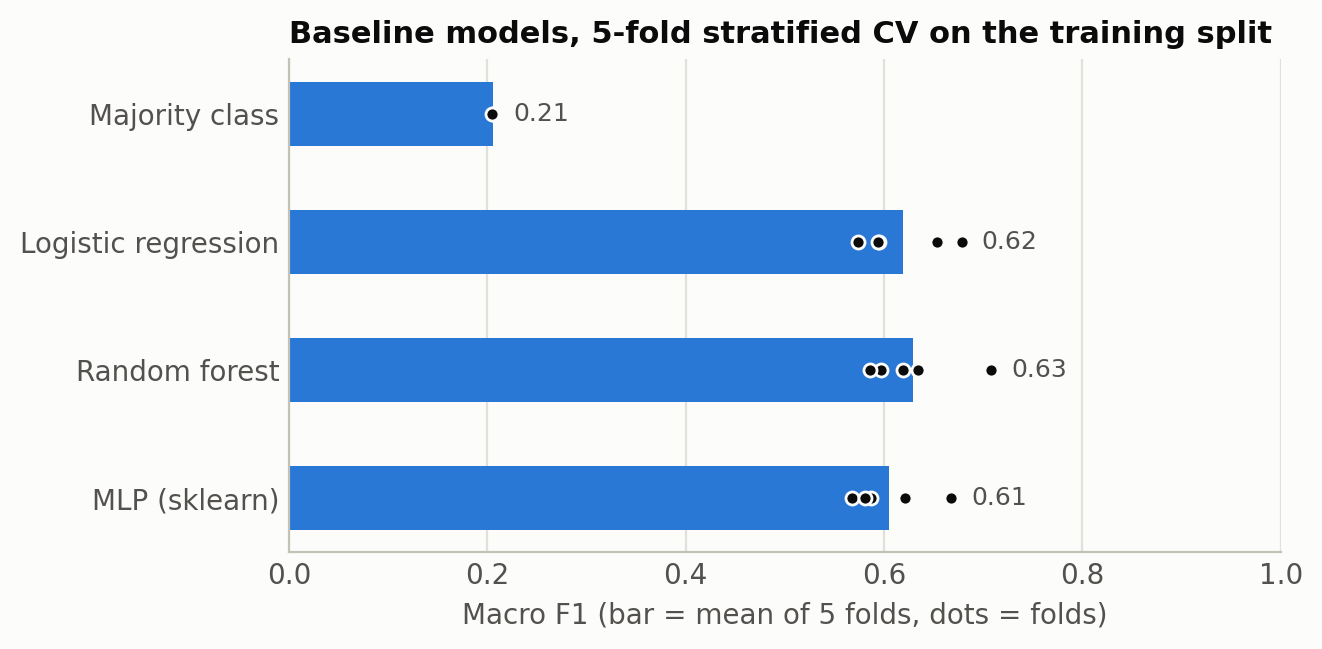

In [3]:
Image("../figures/02_baseline_cv.png", width=640)

The three real models sit within one standard deviation of each other at a macro F1 of about 0.6. The dots are the five folds; the spread (≈ ±0.04) is the honest uncertainty on 736 training rows.

In [4]:
pd.DataFrame(test_rows).set_index("model").round(3)

,accuracy,macro_f1,weighted_f1
model,,,
majority_class,0.446,0.206,0.275
logistic_regression,0.647,0.613,0.644
random_forest,0.652,0.618,0.644
mlp,0.609,0.562,0.595


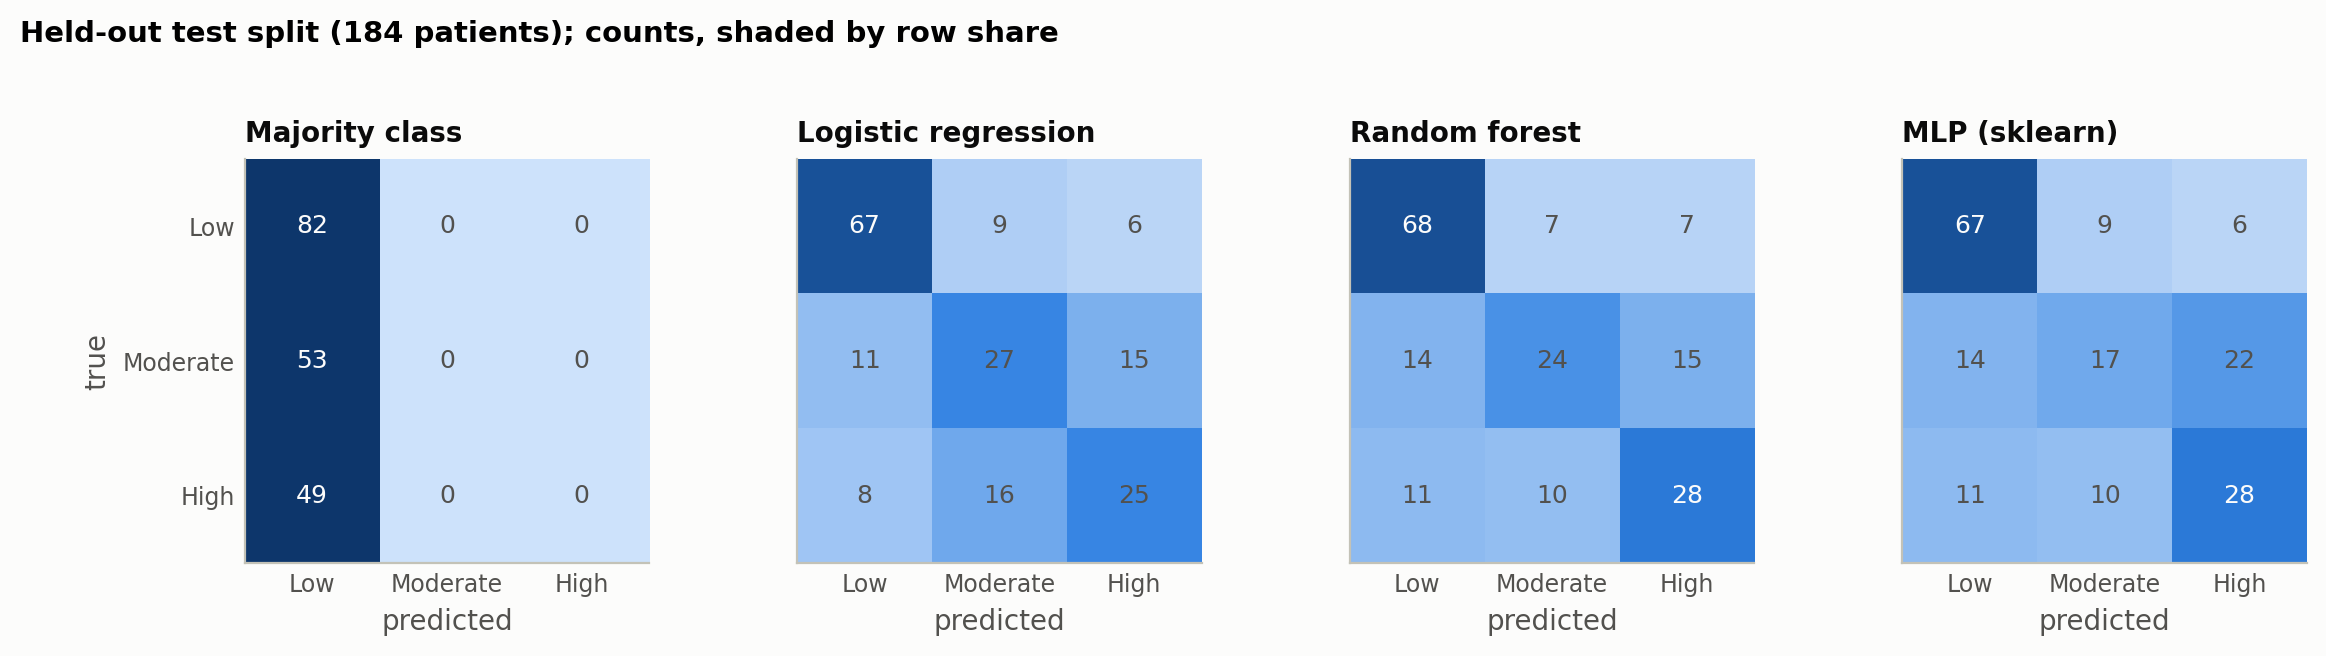

In [5]:
Image("../figures/02_confusion_matrices.png", width=900)

Two things to carry forward:

- **Low is easy, Moderate is hard.** Every model separates *no disease* reasonably, and every model confuses single-vessel (*Moderate*) with both neighbours. That is the ordinal structure of the label showing through.
- **The majority-class floor for this label setup is 0.45 accuracy.** The patent's reported metrics (accuracy 0.43) were computed on class supports that do not match any grouping of `num`, so they come from a different label setup and are not directly comparable; every model here is read against the floor and the baselines instead.

## 2. Per-hospital diagnostic

The source hospital is never a feature. But each site recorded different attributes and has a different case-mix, so a model can look fine overall while failing one site. These are out-of-fold predictions on the training rows (n per site is larger than on the test split).

In [6]:
site = evaluation.per_site(y_train, results[2].oof_pred, train[config.SITE_COL])  # random forest
site.round(3)

,n,accuracy,macro_f1,weighted_f1
site,,,,
Cleveland,242,0.711,0.556,0.678
Hungary,240,0.775,0.756,0.787
Switzerland,97,0.433,0.399,0.452
VA Long Beach,157,0.567,0.534,0.564


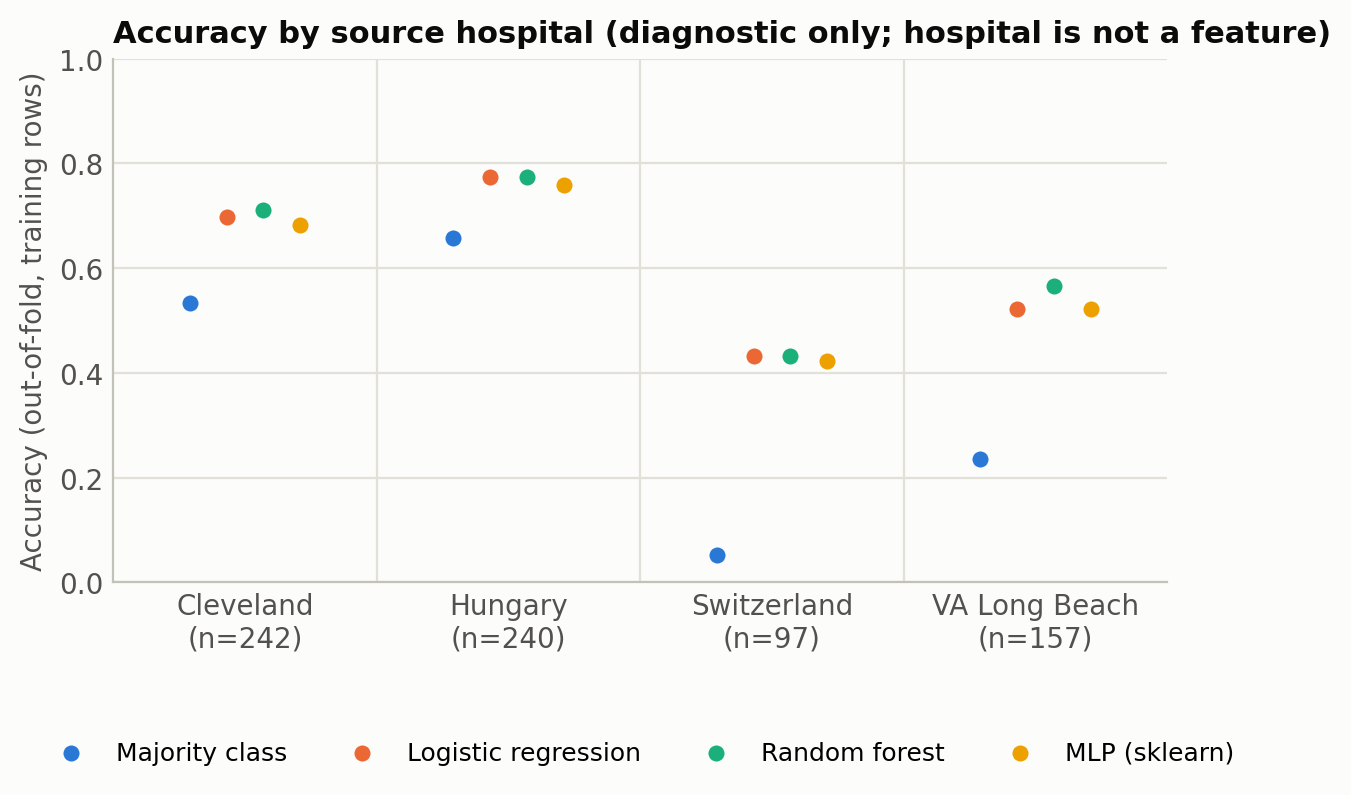

In [7]:
Image("../figures/02_per_site.png", width=680)

Switzerland is the hard site for every model: its patients have no cholesterol values, almost no `ca`, and 93% of them are *Moderate* or *High*, so the imputed-majority values pull predictions towards the wrong classes. Hungary is the easy site because it contains no *High* patients at all. Any later improvement should be checked against this breakdown so that gains on the easy sites do not hide losses on the hard one.

## Outputs

`scripts/phase2_baselines.py` writes the CSV tables to `results/` and the figures to `figures/02_*.png`.

**Next phase:** Binary Brain Storm Optimization over the 13 clinical attributes (via `feature_groups`), scored by cross-validated F1 of a light classifier.